# SPARC rotation curves

Plot the measured rotation curve and velocity uncertainties for each selected SPARC galaxy (Lelli, McGaugh & Schombert, 2016).
Preview one galaxy, then export the full set using the processed tables from notebook 1.

The inclination uncertainty interval must fall within 30 to 80 degrees. The bundled sample has 108 galaxies. Each plot uses its own axis scale and shows the reported velocity errors, which exclude inclination systematics. Stellar mass combines disk and bulge luminosities with mass-to-light ratios of 0.5 and 0.7.

In [ ]:
from pathlib import Path
import sys

# Support launching from the repository root or notebooks/.
PROJECT_ROOT = next(
    (path for path in (Path.cwd(), *Path.cwd().parents)
     if (path / "utils" / "data_loading.py").is_file()
     and (path / "data" / "raw").is_dir()),
    None,
)
if PROJECT_ROOT is None:
    raise RuntimeError("Launch this notebook from within the project directory.")
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import matplotlib.pyplot as plt
import pandas as pd
from utils.plotting import plot_rotation_curve

## Load the selected sample

In [ ]:
DATA_DIR = PROJECT_ROOT / "data" / "processed"
OUTPUT_DIR = PROJECT_ROOT / "figures" / "rotation_curves"
DPI = 300

properties = pd.read_csv(DATA_DIR / "selected_galaxy_properties.csv")
rotation_curves = pd.read_csv(DATA_DIR / "selected_galaxy_rotation_curves.csv").merge(
    properties[["galaxy", "stellar_mass_msun"]], on="galaxy", validate="many_to_one"
)
print(f"{rotation_curves['galaxy'].nunique()} galaxies; {len(rotation_curves):,} measurements")
rotation_curves.head()

## Preview one galaxy
Change `PREVIEW_GALAXY` to inspect another member of the selected sample.

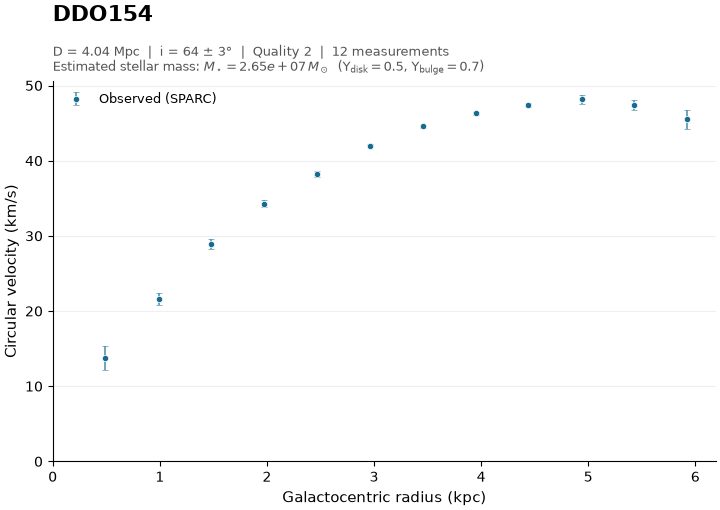

In [3]:
PREVIEW_GALAXY = "DDO154"
preview = rotation_curves.loc[rotation_curves["galaxy"] == PREVIEW_GALAXY]
fig, ax = plot_rotation_curve(preview)
plt.show()
plt.close(fig)

## Export all rotation curves

Save 300-dpi PNGs to `figures/rotation_curves/<galaxy>.png`. Rerunning overwrites matching filenames. Files from earlier sample selections are not removed. Figures are closed after saving to keep memory use bounded.

In [4]:
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
saved_paths = []

for galaxy_name, galaxy in rotation_curves.groupby("galaxy", sort=True):
    fig, ax = plot_rotation_curve(galaxy)
    output_path = OUTPUT_DIR / f"{galaxy_name}.png"
    try:
        fig.savefig(output_path, dpi=DPI, facecolor="white")
        saved_paths.append(output_path)
    finally:
        plt.close(fig)

print(f"Saved {len(saved_paths)} rotation curves to {OUTPUT_DIR}")

Saved 108 rotation curves to C:\Users\anton\Documents\VSCODE PROJECTS\phys_474_halos\figures\rotation_curves
